# Track B: Representation Learning (Santander Product Portfolio)
## Objective
This notebook handles the 'Product Portfolio Module' of our Dual-Track architecture. 
We will load the Santander dataset, extract the 24-product matrix, and prep it for an unsupervised Autoencoder. This will allow us to compress customer product portfolios into dense latent embeddings for clustering.


### Setup & Memory Management
The Santander dataset (`train_ver2.csv`) is 2.3 GB. We will use strict `dtypes` to load it safely. **Make sure you have downloaded `train_ver2.csv` from Kaggle and placed it in `data/santander/`.**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import StandardScaler

# Configure visual settings
sns.set_theme(style='darkgrid', palette='deep')
plt.rcParams['figure.figsize'] = (14, 6)


In [2]:
# We define a subset of dtypes with their ORIGINAL SPANISH names for loading
dtypes = {
    'ncodpers': np.int32, 'age': object, 'antiguedad': object, 'renta': np.float32,
    'ind_nuevo': np.float32, 'indrel': np.float32, 'indrel_1mes': object, 'indext': object,
    'conyuemp': object, 'indfall': object, 'tipodom': np.float32, 'ind_actividad_cliente': np.float32,
    'segmento': object, 'sexo': object, 'tiprel_1mes': object,
    'ind_cco_fin_ult1': np.float32, 'ind_cder_fin_ult1': np.float32, 'ind_cno_fin_ult1': np.float32,
    'ind_ctju_fin_ult1': np.float32, 'ind_ctma_fin_ult1': np.float32, 'ind_ctop_fin_ult1': np.float32,
    'ind_ctpp_fin_ult1': np.float32, 'ind_deco_fin_ult1': np.float32, 'ind_deme_fin_ult1': np.float32,
    'ind_dela_fin_ult1': np.float32, 'ind_ecue_fin_ult1': np.float32, 'ind_fond_fin_ult1': np.float32,
    'ind_hip_fin_ult1': np.float32, 'ind_plan_fin_ult1': np.float32, 'ind_pres_fin_ult1': np.float32,
    'ind_reca_fin_ult1': np.float32, 'ind_tjcr_fin_ult1': np.float32, 'ind_valo_fin_ult1': np.float32,
    'ind_viv_fin_ult1': np.float32, 'ind_nomina_ult1': np.float32, 'ind_nom_pens_ult1': np.float32,
    'ind_recibo_ult1': np.float32, 'nomprov': str, 'fecha_dato': str
}

# Translation dictionary
rename_dict = {
    'ncodpers': 'customer_id', 'age': 'age', 'antiguedad': 'seniority_months', 'renta': 'gross_income',
    'segmento': 'customer_segment', 'sexo': 'gender', 'nomprov': 'province_name', 'fecha_dato': 'snapshot_date',
    'ind_nuevo': 'new_customer_index', 'indrel': 'customer_type', 'indrel_1mes': 'customer_type_primary',
    'indext': 'foreigner_index', 'conyuemp': 'spouse_index', 'indfall': 'deceased_index', 'tipodom': 'address_type',
    'ind_actividad_cliente': 'activity_index', 'tiprel_1mes': 'customer_relation_type',
    'ind_cco_fin_ult1': 'has_current_account', 'ind_cder_fin_ult1': 'has_derivada_account',
    'ind_cno_fin_ult1': 'has_payroll_account', 'ind_ctju_fin_ult1': 'has_junior_account',
    'ind_ctma_fin_ult1': 'has_mas_particular_account', 'ind_ctop_fin_ult1': 'has_particular_account',
    'ind_ctpp_fin_ult1': 'has_particular_plus_account', 'ind_deco_fin_ult1': 'has_short_term_deposits',
    'ind_deme_fin_ult1': 'has_medium_term_deposits', 'ind_dela_fin_ult1': 'has_long_term_deposits',
    'ind_ecue_fin_ult1': 'has_e_account', 'ind_fond_fin_ult1': 'has_funds', 'ind_hip_fin_ult1': 'has_mortgage',
    'ind_plan_fin_ult1': 'has_pensions', 'ind_pres_fin_ult1': 'has_loans', 'ind_reca_fin_ult1': 'has_taxes',
    'ind_tjcr_fin_ult1': 'has_credit_card', 'ind_valo_fin_ult1': 'has_securities', 'ind_viv_fin_ult1': 'has_home_account',
    'ind_nomina_ult1': 'has_payroll', 'ind_nom_pens_ult1': 'has_pensions_nom', 'ind_recibo_ult1': 'has_direct_debit'
}

import subprocess
import random

data_path = '../data/santander/train_ver2.csv'

# To avoid chronological bias (only taking Jan 2015), we load a true random sample.
try:
    print("Calculating total rows in dataset...")
    n_rows = int(subprocess.check_output(['wc', '-l', data_path]).split()[0]) - 1
    
    # Calculate rows to skip (keep 500,000)
    skip = sorted(random.sample(range(1, n_rows + 1), max(0, n_rows - 500000)))
    
    print(f"Loading a true random sample of 500,000 rows from {n_rows} total rows...")
    df = pd.read_csv(data_path, dtype=dtypes, skiprows=skip)
    
    # Rename columns to clean English!
    df.rename(columns=rename_dict, inplace=True)
    
    print(f"Loaded shape: {df.shape}")
except Exception as e:
    print(f"Error loading dataset: {e}")
    df = pd.DataFrame()

Calculating total rows in dataset...


Loading a true random sample of 500,000 rows from 13647309 total rows...


Loaded shape: (500000, 48)


## 1. Demographic Profiling
Before we look at the products, let's understand the base demographics. We need these to explain our final segments (Persona building).


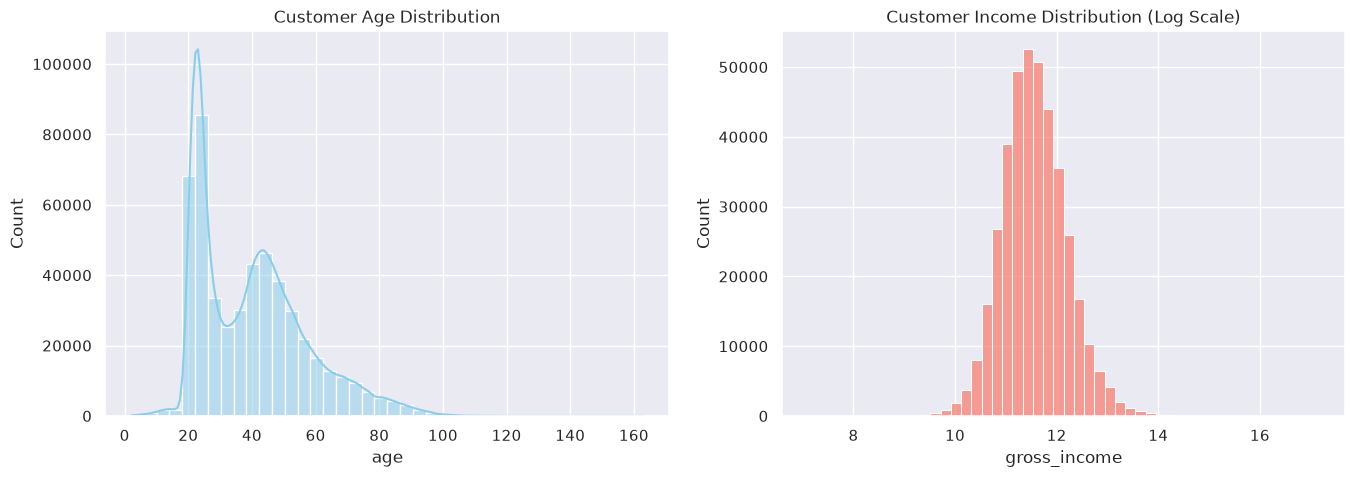

In [3]:
if not df.empty:
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    
    # Age Distribution
    sns.histplot(df['age'].dropna(), bins=40, ax=ax[0], kde=True, color='skyblue')
    ax[0].set_title('Customer Age Distribution')
    
    # Income (Renta) Distribution - Log transformed due to extreme skew
    valid_income = df['gross_income'].dropna()
    sns.histplot(np.log1p(valid_income), bins=50, ax=ax[1], color='salmon')
    ax[1].set_title('Customer Income Distribution (Log Scale)')
    
    plt.show()


## 2. The Autoencoder Input: The 24-Product Matrix
Our goal for Track B is to feed a matrix of product ownership into an Autoencoder. Let's isolate those product columns and look at the sparsity (how many products people actually own).


/tmp/ipykernel_70384/698858450.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Total_Products', palette='viridis')


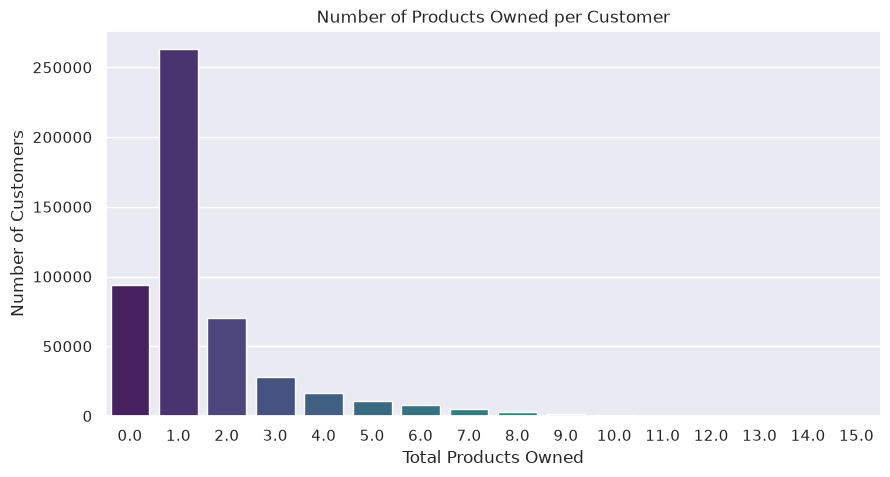

In [4]:
if not df.empty:
    # Identify product columns (starting with 'has_')
    product_cols = [c for c in df.columns if c.startswith('has_')]
    
    # Fill NA values in product columns with 0 (does not own)
    df[product_cols] = df[product_cols].fillna(0)
    
    # Calculate total products owned per customer
    df['Total_Products'] = df[product_cols].sum(axis=1)
    
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x='Total_Products', palette='viridis')
    plt.title('Number of Products Owned per Customer')
    plt.xlabel('Total Products Owned')
    plt.ylabel('Number of Customers')
    plt.show()

## 3. Product Popularity
Which products are most common? This establishes the baseline before clustering.


/tmp/ipykernel_70384/2701589441.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=adoption.head(10).values, y=adoption.head(10).index, palette='mako')


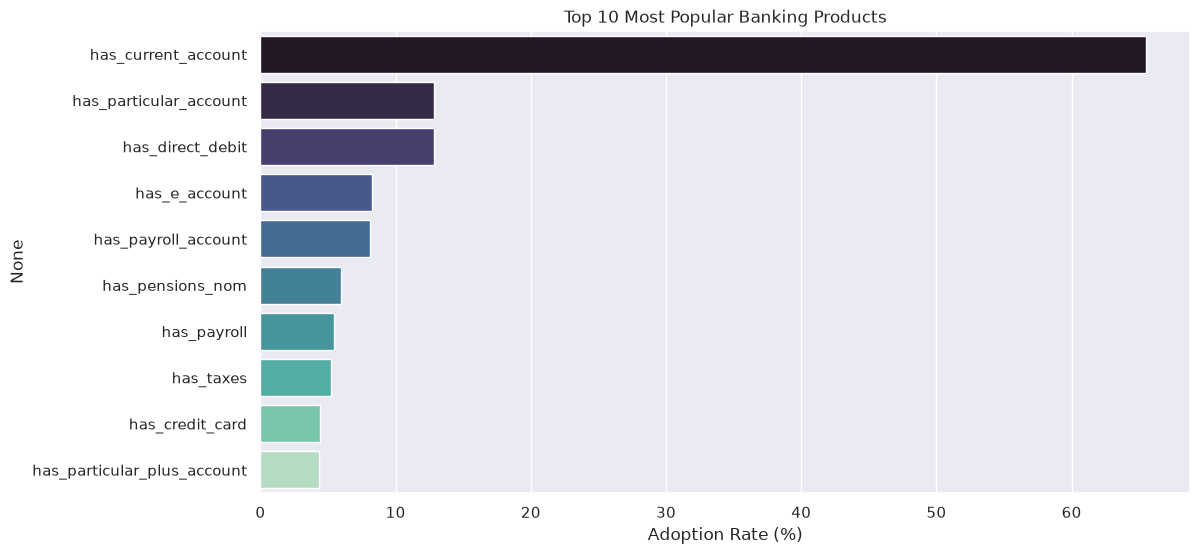

In [5]:
if not df.empty:
    # Calculate adoption rate (%)
    adoption = df[product_cols].mean() * 100
    adoption = adoption.sort_values(ascending=False)
    
    # Plot top 10 products
    plt.figure(figsize=(12, 6))
    sns.barplot(x=adoption.head(10).values, y=adoption.head(10).index, palette='mako')
    plt.title('Top 10 Most Popular Banking Products')
    plt.xlabel('Adoption Rate (%)')
    plt.show()


## 4. Normalization for the Autoencoder
Neural networks require scaled inputs. The product columns are already 0 or 1 (binary), but the demographic columns (Age, Income) need to be standardized using `StandardScaler` so they don't overpower the product matrix during latent space embedding.


In [6]:
if not df.empty:
    features_to_scale = ['age', 'gross_income']
    
    # Drop NaNs for scaling demo
    df_clean = df.dropna(subset=features_to_scale).copy()
    
    scaler = StandardScaler()
    df_scaled = df_clean.copy()
    df_scaled[features_to_scale] = scaler.fit_transform(df_clean[features_to_scale])
    
    print('--- Scaled Demographics Summary ---')
    display(df_scaled[features_to_scale].describe())
    
    print('\n[READY] The dataset is now ready. In the ML pipeline, we will extract the scaled demographics')
    print('and the binary product matrix and feed them directly into the PyTorch Autoencoder.')


--- Scaled Demographics Summary ---


,age,gross_income
count,3.976990e+05,3.976990e+05
mean,-1.417873e-16,-2.915787e-17
std,1.000001e+00,1.000001e+00
min,-2.251014e+00,-6.021937e-01
25%,-9.162577e-01,-2.959564e-01
50%,-4.576424e-02,-1.461876e-01
75%,5.925976e-01,9.901379e-02
max,4.364736e+00,1.303226e+02



[READY] The dataset is now ready. In the ML pipeline, we will extract the scaled demographics
and the binary product matrix and feed them directly into the PyTorch Autoencoder.
